In [1]:
import os
os.environ["XLA_FLAGS"] = (
    r"--xla_gpu_cuda_data_dir=C:\Users\User\Anaconda3\envs\tf210\Library"
)

In [2]:
import os
import random
import time
import pandas as pd

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)
import tensorflow as tf
from tensorflow.keras import models, Sequential, applications, layers
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    CSVLogger,
    ReduceLROnPlateau
)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from tensorflow.keras.optimizers.experimental import AdamW
from tensorflow.keras.utils import image_dataset_from_directory
import keras_tuner as kt

In [3]:
TRAIN_DATA_PATH = "../affectnet_dataset/Train"
TEST_DATA_PATH = "../affectnet_dataset/Test"
EPOCHS = 100
RANDOM_SEED = 40
BATCH_SIZE = 32
IMG_SIZE = (96,96)

SAVED_MODEL = "../saved_models/transfer_kt_model.keras"


In [4]:
# Set global random seeds for reproducibility
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
tf.keras.utils.set_random_seed(RANDOM_SEED)

In [5]:
'''
flow_from_directory is older approach - slower
used image_dataset_from_directory instead for better performance and easier handling of validation split
'''

train_dataset = image_dataset_from_directory(
    TRAIN_DATA_PATH,
    validation_split=0.2,
    subset="training",
    seed = RANDOM_SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode = "int",
    shuffle=True
)

val_dataset = image_dataset_from_directory(
    TRAIN_DATA_PATH,
    validation_split=0.2,
    seed = RANDOM_SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode = "int",
    subset="validation",
)

test_dataset = image_dataset_from_directory(
    TEST_DATA_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode = "int"
)

Found 16108 files belonging to 8 classes.
Using 12887 files for training.
Found 16108 files belonging to 8 classes.
Using 3221 files for validation.
Found 14518 files belonging to 8 classes.


In [6]:
train_counts = {}
CLASSES = train_dataset.class_names
num_classes = len(CLASSES)

for cls in CLASSES:
    cls_folder = os.path.join(TRAIN_DATA_PATH, cls)
    train_counts[cls] = len(os.listdir(cls_folder))

print(train_counts)


{'anger': 1500, 'contempt': 1559, 'disgust': 1229, 'fear': 1512, 'happy': 2340, 'neutral': 2758, 'sad': 3091, 'surprise': 2119}


In [7]:
train_labels = np.concatenate([y.numpy() for _, y in train_dataset])
val_labels = np.concatenate([y.numpy() for _, y in val_dataset])
train_split_counts = np.bincount(
    train_labels.astype(int),
    minlength=num_classes
)
val_split_counts =np.bincount(
    val_labels.astype(int),
    minlength=num_classes
)
distribution = pd.DataFrame({
    "Emotions": CLASSES,
    "Train Counts": train_split_counts,
    "Train (%)": train_split_counts/train_split_counts.sum() * 100,
    "Val Counts": val_split_counts,
    "Val (%)": val_split_counts/val_split_counts.sum() * 100,
})
print(distribution.round(2))

   Emotions  Train Counts  Train (%)  Val Counts  Val (%)
0     anger          1195       9.27         305     9.47
1  contempt          1250       9.70         309     9.59
2   disgust           989       7.67         240     7.45
3      fear          1191       9.24         321     9.97
4     happy          1864      14.46         476    14.78
5   neutral          2198      17.06         560    17.39
6       sad          2505      19.44         586    18.19
7  surprise          1695      13.15         424    13.16


In [8]:
'''
Compute class weights from train splitted part only (imbalanced data)
- train_labels is an array of all labels from train dataset.
- concetenate() is used to combine all batches of labels into array
for class weight computation
- y.numpy() is used to convert tensor to numpy array for class weight computation
Class weights змушують loss сильніше штрафувати помилки на rare classes.
'''

train_labels = np.concatenate([y.numpy() for _, y in train_dataset], axis=0)
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=train_labels
)
class_weights = dict(enumerate(class_weights_array))

print("Class names:", CLASSES)
print("Class weights:", class_weights)

Class names: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Class weights: {0: 1.3480125523012552, 1: 1.2887, 2: 1.6287917087967645, 3: 1.3525398824517212, 4: 0.8642033261802575, 5: 0.7328821656050956, 6: 0.643063872255489, 7: 0.9503687315634218}


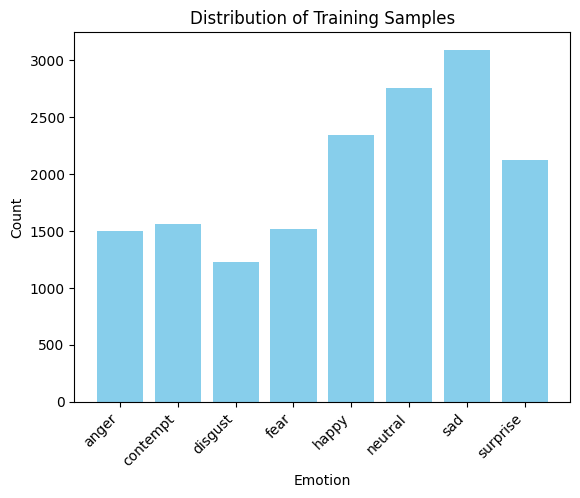

In [9]:
plt.bar(train_counts.keys(), train_counts.values(), color='skyblue')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.title('Distribution of Training Samples')
plt.show()

In [10]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal", seed=RANDOM_SEED),
    layers.RandomRotation(0.05, seed=RANDOM_SEED), # 0.1
    layers.RandomZoom(0.05, seed=RANDOM_SEED),
], name="data_augmentation")

In [11]:
base_model = applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False, # rm last classification block
    weights = "imagenet" # take weights pretrained on imagenet
)
# Freeze base block
base_model.trainable = False

In [12]:
print(base_model.name)
print(base_model.trainable)

mobilenetv2_1.00_96
False


In [13]:
# Functional API for more flexibility in architecture and hp tuning
def build_model(hp):
    dropout = hp.Float("dropout", 0.2, 0.5, step=0.1)

    dense_units1 = hp.Choice("dense_units1", [128, 256, 512])
    dense_units2 = hp.Choice("dense_units2", [128, 256, 512])

    l2 = hp.Float("l2_3", 1e-5, 1e-3, sampling="log")
    lr = hp.Float("lr", 1e-4, 1e-3, sampling="log")

    model = Sequential([    
        layers.Input(shape=(*IMG_SIZE, 3)),
        data_augmentation,
        layers.Rescaling(scale=1./127.5, offset=-1),
        base_model,
        layers.GlobalAveragePooling2D(),

        layers.Dense(
            dense_units1,
            kernel_regularizer=tf.keras.regularizers.l2(l2)
            ),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(dropout),

        layers.Dense(
            dense_units2,
            kernel_regularizer=tf.keras.regularizers.l2(l2)
        ),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(dropout),

        layers.Dense(num_classes, activation='softmax'),
    ])

    optimizer = AdamW(
        learning_rate=lr,
        weight_decay=l2
    )

    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=optimizer,
        metrics=['accuracy']
    )
    return model

In [14]:
es = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )
rlr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5, #0.5
    patience=3, #5
    min_lr=1e-6
    )

In [15]:
'''
Initialize a tuner (here, RandomSearch). 
We use objective to specify the objective to select the best models,
and we use max_trials to specify the number of different models to try.
'''
def make_random_search(build_model, project_name, objective, max_trials):
    return kt.RandomSearch(
            hypermodel=build_model,
            objective=kt.Objective(objective, direction="min"),
            max_trials=max_trials,
            executions_per_trial=2, # helps to reduce variance by training each model multiple times
            overwrite=True,
            directory='keras_tuner_results',
            project_name=project_name
        )

In [16]:
tuner = make_random_search(
    build_model,
    project_name="cnn_random",
    objective="val_loss",
    max_trials=10
)

In [17]:
tuner.search(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=[rlr, es]
)

Trial 10 Complete [00h 18m 37s]
val_loss: 1.7717693448066711

Best val_loss So Far: 1.4544948935508728
Total elapsed time: 03h 51m 15s


In [18]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model = tuner.hypermodel.build(best_hp)

In [19]:
best_hp.values

{'dropout': 0.4,
 'dense_units1': 128,
 'dense_units2': 128,
 'l2_3': 1.0579751249183486e-05,
 'lr': 0.0005169386810880218}

In [20]:
tuner.results_summary()

Results summary
Results in keras_tuner_results\cnn_random
Showing 10 best trials
Objective(name="val_loss", direction="min")

Trial 03 summary
Hyperparameters:
dropout: 0.4
dense_units1: 128
dense_units2: 128
l2_3: 1.0579751249183486e-05
lr: 0.0005169386810880218
Score: 1.4544948935508728

Trial 08 summary
Hyperparameters:
dropout: 0.2
dense_units1: 128
dense_units2: 128
l2_3: 3.861184507000286e-05
lr: 0.0003297548445254004
Score: 1.4873129725456238

Trial 02 summary
Hyperparameters:
dropout: 0.2
dense_units1: 512
dense_units2: 512
l2_3: 2.2023203381828495e-05
lr: 0.0006132468318948925
Score: 1.5491527915000916

Trial 06 summary
Hyperparameters:
dropout: 0.2
dense_units1: 512
dense_units2: 256
l2_3: 5.0796803023399925e-05
lr: 0.00014391747930018716
Score: 1.5554606914520264

Trial 00 summary
Hyperparameters:
dropout: 0.2
dense_units1: 512
dense_units2: 512
l2_3: 6.634068043893112e-05
lr: 0.00014215852904294834
Score: 1.5844546556472778

Trial 07 summary
Hyperparameters:
dropout: 0.4
de

In [21]:
best_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 data_augmentation (Sequenti  (None, 96, 96, 3)        0         
 al)                                                             
                                                                 
 rescaling_1 (Rescaling)     (None, 96, 96, 3)         0         
                                                                 
 mobilenetv2_1.00_96 (Functi  (None, 3, 3, 1280)       2257984   
 onal)                                                           
                                                                 
 global_average_pooling2d_1   (None, 1280)             0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dense_3 (Dense)             (None, 128)               163968    
                                                      

In [22]:
callbacks_stage1 = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        SAVED_MODEL,
        monitor='val_loss', 
        save_best_only=True
    ),
    CSVLogger('training_log_stage1.csv'),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5, #0.5
        patience=3, #5
        min_lr=1e-6
    )
]

In [23]:
# STAGE 1 - training frozen backbone
start = time.time()
history = best_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=50,
    class_weight=class_weights,
    callbacks=callbacks_stage1
)
end = time.time()
elapsed_time = end - start

print("Training time: ", time.strftime("%H:%M:%S", time.gmtime(elapsed_time)))

Epoch 1/50
403/403 [==============================] - 62s 145ms/step - loss: 1.9234 - accuracy: 0.2825 - val_loss: 1.8735 - val_accuracy: 0.2949 - lr: 5.1694e-04
Epoch 2/50
403/403 [==============================] - 74s 184ms/step - loss: 1.6365 - accuracy: 0.3440 - val_loss: 1.7164 - val_accuracy: 0.3244 - lr: 5.1694e-04
Epoch 3/50
403/403 [==============================] - 89s 221ms/step - loss: 1.5553 - accuracy: 0.3643 - val_loss: 1.5688 - val_accuracy: 0.3620 - lr: 5.1694e-04
Epoch 4/50
403/403 [==============================] - 89s 220ms/step - loss: 1.5148 - accuracy: 0.3847 - val_loss: 1.5509 - val_accuracy: 0.3788 - lr: 5.1694e-04
Epoch 5/50
403/403 [==============================] - 88s 218ms/step - loss: 1.4802 - accuracy: 0.4041 - val_loss: 1.5736 - val_accuracy: 0.3785 - lr: 5.1694e-04
Epoch 6/50
403/403 [==============================] - 89s 220ms/step - loss: 1.4682 - accuracy: 0.4086 - val_loss: 1.6196 - val_accuracy: 0.3757 - lr: 5.1694e-04
Epoch 7/50
403/403 [========

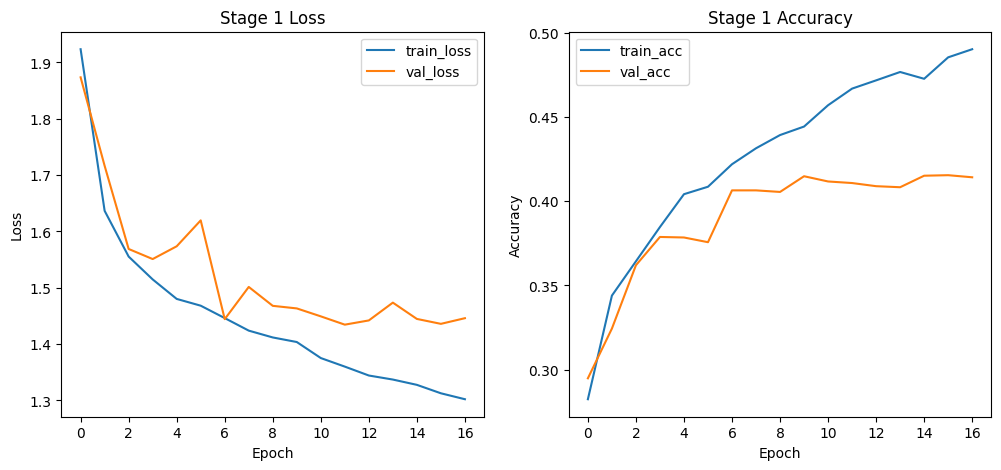

In [24]:
plt.figure(figsize=(12,5))

# Loss
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Stage 1 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Accuracy
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.title('Stage 1 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [25]:
model = models.load_model(SAVED_MODEL)

In [35]:
train_loss, train_acc = model.evaluate(train_dataset, verbose=0)
val_loss, val_acc = model.evaluate(val_dataset, verbose=0)

print(f"train loss: {train_loss:.2f}")
print(f"val loss: {val_loss:.2f}")
print(f"train accuracy: {train_acc*100:.2f}")
print(f"val accuracy: {val_acc*100:.2f}")

train loss: 1.33
val loss: 1.43
train accuracy: 47.13
val accuracy: 41.07


In [36]:
test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print(f"Test loss: {test_loss:.2f}")
print(f"Test accuracy: {test_acc*100:.2f}")

Test loss: 1.85
Test accuracy: 43.79


In [37]:
y_prob = model.predict(test_dataset, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.concatenate([y.numpy() for _, y in test_dataset], axis=0)

macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"Macro F1: {macro_f1*100:.2f}")
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    zero_division=0
))

Macro F1: 38.70
              precision    recall  f1-score   support

       anger       0.35      0.42      0.38      1718
    contempt       0.32      0.51      0.39      1312
     disgust       0.26      0.26      0.26      1248
        fear       0.50      0.26      0.34      1664
       happy       0.62      0.66      0.64      2704
     neutral       0.48      0.76      0.59      2368
         sad       0.38      0.16      0.23      1584
    surprise       0.39      0.21      0.27      1920

    accuracy                           0.44     14518
   macro avg       0.41      0.40      0.39     14518
weighted avg       0.44      0.44      0.42     14518



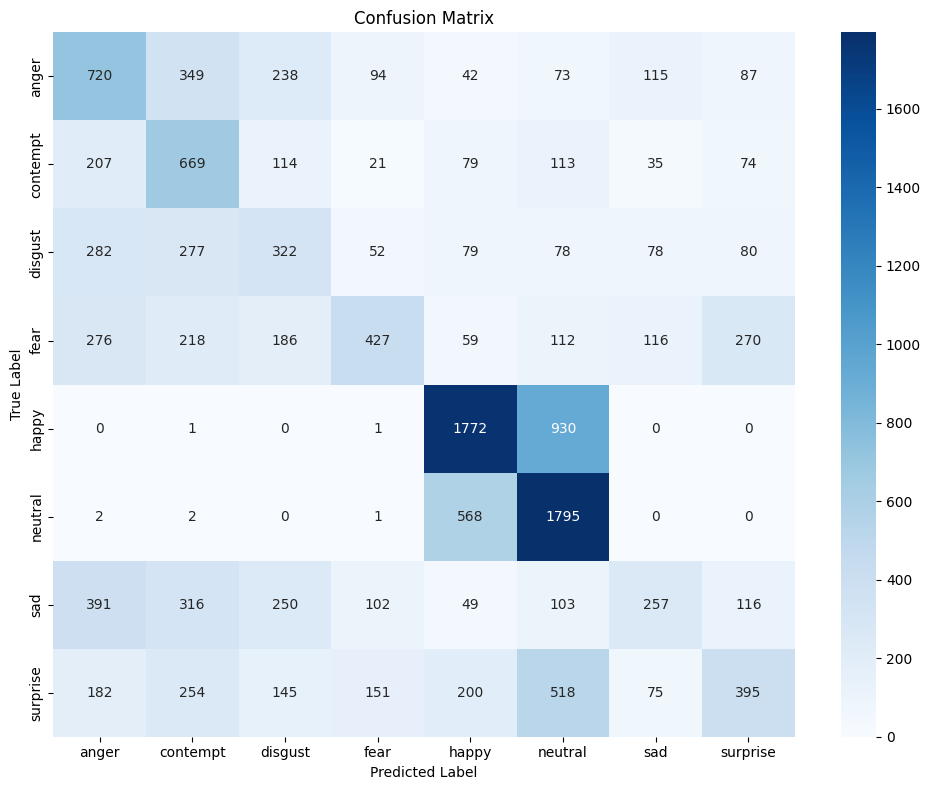

In [38]:
cm = confusion_matrix(
    y_true,
    y_pred,
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [40]:
# Divide by 1024**2 to convert bytes to megabytes
size_mb = os.path.getsize(SAVED_MODEL) / (1024**2)

print(f"Model size: {size_mb:.2f} MB")

Model size: 9.62 MB


In [41]:
def measure_peak_memory(model, x, device="GPU:0"):
    # обнуляєм стати памяті
    tf.config.experimental.reset_memory_stats(device)
    # проганяєм модель на вході x (forward pass)
    y = model(tf.convert_to_tensor(x), training=False)
    # _ - placeholder для результату
    # y.numpy() - примусити TensorFlow виконати обчислення і оновити статистику пам'яті
    _ = y.numpy()
    # отримуємо інформацію про використання пам'яті
    info = tf.config.experimental.get_memory_info(device)
    # переводимо байти в мегабайти
    peak_mb = info["peak"] / (1024**2)
    current_mb = info["current"] / (1024**2)
    return peak_mb, current_mb

In [42]:
# тестуємо функцію на випадковому вході, який відповідає розміру зображення
input = tf.random.normal((1, 96, 96, 3))
peak_mb, current_mb = measure_peak_memory(
    model,
    input
)

print(f"CNN Peak Memory: {peak_mb:.2f} MB")
print(f"CNN Current Memory: {current_mb:.2f} MB")

CNN Peak Memory: 75.55 MB
CNN Current Memory: 73.70 MB


In [43]:
x_batch, y_batch = next(iter(test_dataset.take(1)))
x1 = x_batch[:1]

_ = model(x1, training=False)

start = time.perf_counter()
for _ in range(100):
    _ = model(x1, training=False)
end = time.perf_counter()

latency_ms = (end - start) / 100 * 1000
print(f"Latency per sample: {latency_ms:.2f} ms")

Latency per sample: 26.72 ms


In [44]:
from tensorflow.python.profiler.model_analyzer import profile
from tensorflow.python.profiler.option_builder import ProfileOptionBuilder

def get_model_flops(model, input_shape=None):
        
    # 1. Convert the Keras model call into a concrete TensorFlow function graph
    forward_pass = tf.function(model.call, input_signature=[tf.TensorSpec(shape=input_shape, dtype=model.compute_dtype)])
    graph = forward_pass.get_concrete_function().graph
    
    # 2. Configure the profiler options to extract floating point operations
    options = ProfileOptionBuilder.float_operation()
    
    # 3. Profile the graph and retrieve total float ops
    graph_info = profile(graph, options=options)
    total_flops = graph_info.total_float_ops
    
    print(f"Total FLOPs: {total_flops:,} ({total_flops / 1e9:.4f} GFLOPs)")
    
    return total_flops

In [45]:
flops = get_model_flops(model, input_shape=(1, 96, 96, 3))

Total FLOPs: 110,421,808 (0.1104 GFLOPs)
